# Divide y vencerás

Un problema se parte en $a$ subproblemas del mismo tipo de tamaño $n/b$, se resuelven recursivamente y se combinan sus soluciones con un coste $f(n)$. El coste total cumple la recurrencia

$$T(n) = a \, T(n / b) + f(n)$$

y, si $f(n) = \Theta(n^d)$, el teorema maestro la resuelve comparando $d$ con $\log_b a$: $\Theta(n^d)$ si $d > \log_b a$, $\Theta(n^d \log n)$ si son iguales y $\Theta(n^{\log_b a})$ si $d < \log_b a$. Así la ordenación por mezcla ($a = b = 2$, $d = 1$) cuesta $O(n \log n)$ y Karatsuba ($a = 3$, $b = 2$, $d = 1$) cuesta $O(n^{1.585})$.

## 1. Exponenciación rápida

Calcular $x^n$ con $O(\log n)$ multiplicaciones usando $x^n = (x^{n/2})^2$ si $n$ es par y $x \cdot x^{n-1}$ si es impar. Contar las multiplicaciones frente al producto repetido, comprobar contra `**` y aplicarlo a matrices $2 \times 2$ para obtener el Fibonacci $F_n$ de $\begin{pmatrix} 1 & 1 \\ 1 & 0 \end{pmatrix}^n$.

In [1]:
import random

def potencia(x, n, multiplica=lambda a, b: a * b, uno=1, contador=None):
    if n == 0:
        return uno
    if n % 2:
        resultado = multiplica(x, potencia(x, n - 1, multiplica, uno, contador))
    else:
        mitad = potencia(x, n // 2, multiplica, uno, contador)
        resultado = multiplica(mitad, mitad)
    if contador is not None:
        contador[0] += 1
    return resultado

for n in (10, 100, 1000, 10**6):
    contador = [0]
    assert potencia(3, n, contador=contador) == 3 ** n
    print(f"n = {n:>8}: {contador[0]:3} multiplicaciones en lugar de {n - 1}")

def mult_matriz(A, B):
    return [[sum(A[i][k] * B[k][j] for k in range(2)) for j in range(2)] for i in range(2)]

def fibonacci(n):
    return potencia([[1, 1], [1, 0]], n, mult_matriz, [[1, 0], [0, 1]])[0][1]

a, b = 0, 1
for n in range(300):
    assert fibonacci(n) == a
    a, b = b, a + b
print(fibonacci(100), len(str(fibonacci(10**4))), "cifras tiene F(10000)")

n =       10:   5 multiplicaciones en lugar de 9
n =      100:   9 multiplicaciones en lugar de 99
n =     1000:  15 multiplicaciones en lugar de 999
n =  1000000:  26 multiplicaciones en lugar de 999999
354224848179261915075 2090 cifras tiene F(10000)


## 2. Contar inversiones con la ordenación por mezcla

Una inversión es un par $i < j$ con $a_i > a_j$, y mide lo desordenada que está una lista. Contarlas en $O(n \log n)$ aprovechando la mezcla: cuando se toma un elemento de la mitad derecha, forma inversión con todos los que quedan en la izquierda. Comprobarlo contra el doble bucle $O(n^2)$ y comparar tiempos.

In [2]:
import time

def ordena_y_cuenta(a):
    if len(a) <= 1:
        return a, 0
    medio = len(a) // 2
    izq, inv_izq = ordena_y_cuenta(a[:medio])
    der, inv_der = ordena_y_cuenta(a[medio:])
    mezcla, i, j, cruzadas = [], 0, 0, 0
    while i < len(izq) and j < len(der):
        if izq[i] <= der[j]:
            mezcla.append(izq[i])
            i += 1
        else:
            mezcla.append(der[j])
            cruzadas += len(izq) - i
            j += 1
    return mezcla + izq[i:] + der[j:], inv_izq + inv_der + cruzadas

def inversiones_fuerza_bruta(a):
    return sum(a[i] > a[j] for i in range(len(a)) for j in range(i + 1, len(a)))

random.seed(1)
for _ in range(500):
    a = [random.randint(0, 20) for _ in range(random.randint(0, 30))]
    ordenada, inv = ordena_y_cuenta(a)
    assert ordenada == sorted(a) and inv == inversiones_fuerza_bruta(a)

print(ordena_y_cuenta([2, 4, 1, 3, 5])[1], ordena_y_cuenta(list(range(10, 0, -1)))[1])
datos = [random.random() for _ in range(3000)]
for f in (lambda a: ordena_y_cuenta(a)[1], inversiones_fuerza_bruta):
    inicio = time.perf_counter()
    resultado = f(datos)
    print(f"{resultado} inversiones en {time.perf_counter() - inicio:.3f} s")

3 45
2232572 inversiones en 0.004 s


2232572 inversiones en 0.155 s


## 3. Multiplicación de Karatsuba

Para multiplicar dos números de $n$ cifras, partirlos en mitades $x = x_1 B + x_0$, $y = y_1 B + y_0$ y usar solo tres productos: $z_2 = x_1 y_1$, $z_0 = x_0 y_0$ y $z_1 = (x_1 + x_0)(y_1 + y_0) - z_2 - z_0$, de modo que $x y = z_2 B^2 + z_1 B + z_0$. Contar los productos de una cifra frente a los $n^2$ del método escolar, comprobar contra `*` y dibujarlo.

{2: 3, 4: 13, 8: 35, 16: 113, 32: 363, 64: 1047, 128: 3293, 256: 9427, 512: 28767, 1024: 86119}


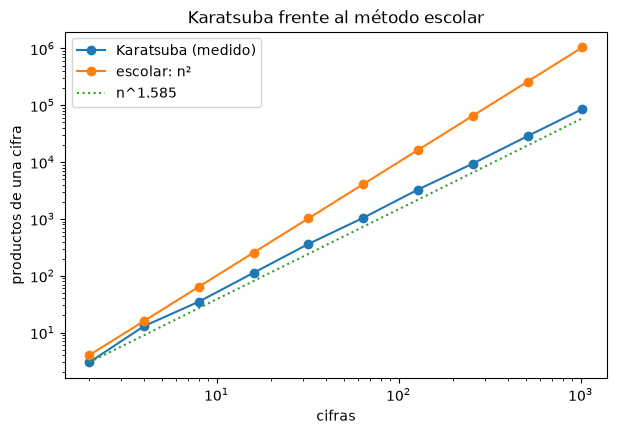

In [3]:
import matplotlib.pyplot as plt

def karatsuba(x, y, contador):
    if x < 10 or y < 10:
        contador[0] += 1
        return x * y
    m = max(len(str(x)), len(str(y))) // 2
    B = 10 ** m
    x1, x0 = divmod(x, B)
    y1, y0 = divmod(y, B)
    z2 = karatsuba(x1, y1, contador)
    z0 = karatsuba(x0, y0, contador)
    z1 = karatsuba(x1 + x0, y1 + y0, contador) - z2 - z0
    return z2 * B * B + z1 * B + z0

random.seed(2)
for _ in range(500):
    x, y = random.randint(0, 10 ** random.randint(1, 60)), random.randint(0, 10 ** random.randint(1, 60))
    assert karatsuba(x, y, [0]) == x * y

cifras = [2 ** k for k in range(1, 11)]
productos = []
for n in cifras:
    contador = [0]
    karatsuba(random.randint(10 ** (n - 1), 10 ** n - 1), random.randint(10 ** (n - 1), 10 ** n - 1), contador)
    productos.append(contador[0])
print(dict(zip(cifras, productos)))

fig, eje = plt.subplots(figsize=(7, 4.5))
eje.plot(cifras, productos, "o-", label="Karatsuba (medido)")
eje.plot(cifras, [n ** 2 for n in cifras], "o-", label="escolar: n²")
eje.plot(cifras, [n ** 1.585 for n in cifras], ":", label="n^1.585")
eje.set(xscale="log", yscale="log", xlabel="cifras", ylabel="productos de una cifra", title="Karatsuba frente al método escolar")
eje.legend()
plt.show()

## 4. Par de puntos más cercano

Encontrar los dos puntos más cercanos de una nube en $O(n \log n)$: ordenar por $x$, resolver cada mitad, y con $\delta$ la menor distancia de las dos mitades mirar solo la franja de anchura $2\delta$ alrededor de la línea divisoria, ordenada por $y$, donde cada punto solo tiene que compararse con los 7 siguientes. Comprobarlo contra fuerza bruta, comparar tiempos y dibujar el par.

divide y vencerás  0.000222 en 0.005 s


fuerza bruta       0.000222 en 0.265 s


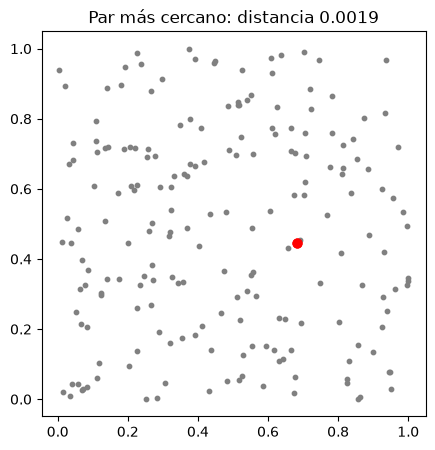

In [4]:
import math
from itertools import combinations

def par_mas_cercano(puntos):
    def resuelve(por_x):
        n = len(por_x)
        if n <= 3:
            return min(((math.dist(p, q), p, q) for p, q in combinations(por_x, 2)), default=(math.inf, None, None))
        medio = n // 2
        x_medio = por_x[medio][0]
        mejor = min(resuelve(por_x[:medio]), resuelve(por_x[medio:]))
        franja = sorted((p for p in por_x if abs(p[0] - x_medio) < mejor[0]), key=lambda p: p[1])
        for i, p in enumerate(franja):
            for q in franja[i + 1:i + 8]:
                if q[1] - p[1] >= mejor[0]:
                    break
                mejor = min(mejor, (math.dist(p, q), p, q))
        return mejor
    return resuelve(sorted(puntos))

def par_fuerza_bruta(puntos):
    return min(math.dist(p, q) for p, q in combinations(puntos, 2))

random.seed(3)
for _ in range(300):
    puntos = [(random.randint(0, 50), random.randint(0, 50)) for _ in range(random.randint(2, 40))]
    assert par_mas_cercano(puntos)[0] == par_fuerza_bruta(puntos)

nube = [(random.random(), random.random()) for _ in range(3000)]
for nombre, f in (("divide y vencerás", lambda p: par_mas_cercano(p)[0]), ("fuerza bruta", par_fuerza_bruta)):
    inicio = time.perf_counter()
    distancia = f(nube)
    print(f"{nombre:18} {distancia:.6f} en {time.perf_counter() - inicio:.3f} s")

nube = [(random.random(), random.random()) for _ in range(200)]
d, p, q = par_mas_cercano(nube)
fig, eje = plt.subplots(figsize=(5, 5))
eje.scatter(*zip(*nube), s=10, color="gray")
eje.scatter(*zip(p, q), s=40, color="red")
eje.add_patch(plt.Circle(p, d, fill=False, color="red"))
eje.set_title(f"Par más cercano: distancia {d:.4f}")
eje.set_aspect("equal")
plt.show()

## 5. Recurrencias y teorema maestro

Escribir una función que, dados $a$, $b$ y $d$, diga qué caso del teorema maestro aplica y el coste resultante. Comprobarlo calculando $T(n) = a T(n/b) + n^d$ (con $T(1) = 1$) para potencias de $b$ y dibujando el cociente $T(n) / g(n)$, que debe tender a una constante, para la búsqueda binaria, la ordenación por mezcla, Karatsuba, Strassen y un caso con $d > \log_b a$.

búsqueda binaria a=1 b=2 d=0: Θ(log n)         T/g -> 1.515
mezcla           a=2 b=2 d=1: Θ(n^1 log n)     T/g -> 1.515
Karatsuba        a=3 b=2 d=1: Θ(n^1.585)       T/g -> 2.999
Strassen         a=7 b=2 d=2: Θ(n^2.807)       T/g -> 2.333
a=2, b=2, d=2    a=2 b=2 d=2: Θ(n^2)           T/g -> 2.000


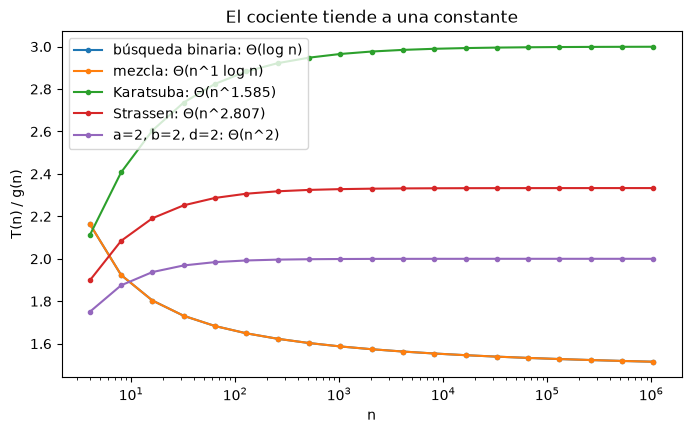

In [5]:
from functools import cache

def teorema_maestro(a, b, d):
    critico = math.log(a, b)
    if math.isclose(d, critico):
        return "Θ(n^%g log n)" % d if d else "Θ(log n)", lambda n: n ** d * math.log(n)
    if d > critico:
        return "Θ(n^%g)" % d, lambda n: n ** d
    return "Θ(n^%.3f)" % critico, lambda n: n ** critico

def recurrencia(a, b, d):
    @cache
    def T(n):
        return 1 if n <= 1 else a * T(n // b) + n ** d
    return T

casos = {"búsqueda binaria": (1, 2, 0), "mezcla": (2, 2, 1), "Karatsuba": (3, 2, 1),
         "Strassen": (7, 2, 2), "a=2, b=2, d=2": (2, 2, 2)}
fig, eje = plt.subplots(figsize=(8, 4.5))
for nombre, (a, b, d) in casos.items():
    coste, g = teorema_maestro(a, b, d)
    T = recurrencia(a, b, d)
    ns = [b ** k for k in range(2, 21)]
    cocientes = [T(n) / g(n) for n in ns]
    assert cocientes[-1] / cocientes[-2] < 1.1  # se estabiliza
    print(f"{nombre:16} a={a} b={b} d={d}: {coste:16} T/g -> {cocientes[-1]:.3f}")
    eje.plot(ns, cocientes, "o-", markersize=3, label=f"{nombre}: {coste}")
eje.set(xscale="log", xlabel="n", ylabel="T(n) / g(n)", title="El cociente tiende a una constante")
eje.legend()
plt.show()